# Expected-time ensemble: deposit-disjoint training and feasible scheduling

**Question:** Does the learned policy transfer to unseen deposits well enough to complement exact expected-time ordering?

**Level:** 4 · proposed methods. **Reading time:** 45 minutes.


## Objectives

This worked experiment studies a deployable scheduling policy, not a generic neural-network tutorial. Its decision is a block ordering; its output is a feasible schedule. The downstream precedence and capacity rules remain the same as for the reference comparator. The target is expected extraction time, scaled by the horizon. This target is useful because the existing exact ExTS heuristic orders blocks by expected extraction time before constructing a schedule. The learned policy approximates that ordering from features available to the pipeline. Training and evaluation are separated by deposit seed. This is stricter than splitting individual blocks: blocks from one synthetic deposit share geometry and geological structure, so a row split can place close relatives on both sides. The holdout therefore asks about transfer to new generated deposits. Five members share the training data but use distinct fixed initialization seeds. Their mean is the deployed prediction. This ensemble measures initialization sensitivity; it does not represent independent geological realizations or a calibrated posterior distribution.

## Setup

Run from the repository root with `pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2`; exact pins: `oreblocks==0.6.5`, `numpy==2.5.1`, `scipy==1.18.1`, `matplotlib==3.11.2`. The lesson reads the released model bundle and training report, never retrains or installs packages in a cell. A fresh kernel reconstructs each table and figure.

```bash
pip install oreblocks==0.6.5 numpy==2.5.1 scipy==1.18.1 matplotlib==3.11.2
```

In [1]:
# Import pinned tools, load the released method and show the environment versions.
import importlib.metadata as package_metadata
import json
import sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
ROOT = Path('../../../').resolve()
sys.path.insert(0, str(ROOT / 'data-pipeline'))
from pipeline.model.learned import LearnedBundle  # noqa: E402
from pipeline.model.features import BLOCK_FEATURES  # noqa: E402
from pipeline.io.schema import Case, DepositSpec, Scenario  # noqa: E402
from pipeline.model.instances import build_instance  # noqa: E402
report = json.loads((ROOT / 'models/training-report.json').read_text(encoding='utf-8'))
bundle = LearnedBundle.load(ROOT / 'models')
metrics = bundle.report()['expectedTime']
for package in ('oreblocks','numpy','scipy','matplotlib'):
    print(package, package_metadata.version(package))
print('block features:', len(BLOCK_FEATURES), '| ensemble members:', len(bundle.expected_time.members)+1)
print('holdout seeds:', metrics['holdout_seeds'])


oreblocks 0.6.5
numpy 2.5.1
scipy 1.18.1
matplotlib 3.11.2
block features: 11 | ensemble members: 5
holdout seeds: [211, 223, 227, 229, 233, 239]


## Data

At inference, the model calculates eleven ordered block features, applies training-only normalization, predicts a bounded fraction, and converts it to expected periods. TopoSort then builds a schedule under the precedence graph and capacities. Neither the prediction nor the schedule certifies an upper bound. Exact expected-time ordering is the nearest comparator because it uses the same scheduling constructor with the target known. Sliding-window MILP, destination-choice formulations, and local search provide additional context but solve different restricted problems. Results must retain their method labels. The primary utility measure is discounted NPV divided by the exact ExTS schedule NPV on the same case. Rank correlation diagnoses ordering, but can hide economically important inversions. Feasibility is a hard requirement, while solve time and failure tails help determine when a fast heuristic is useful.

Construct the reproducible small deposit with the product pipeline.


In [2]:
# Construct a bounded teaching case with a declared seed and two resources.
case = Case(
    id='bs1-vein-8x8x4', category='teaching',
    title_en='BS1 vein', title_es='Veta BS1',
    deposit=DepositSpec(
        kind='twin', archetype='vein', dims=(8,8,4), seed=223,
    ),
    scenario=Scenario(
        periods=6, discount_rate=0.10,
        capacity_fraction=(0.85,0.55),
        resource_names=('mining','processing'),
    ),
)
instance = build_instance(case)
print('teaching contract:', instance.report.ok, '| blocks:', instance.n_blocks)

teaching contract: True | blocks: 256


## Method

The benchmark uses synthetic deposits with declared geometry, seeds, capacities, discount and scenario generation. Synthetic control permits repeatability, but it cannot establish transfer to a mine with conditioning data, operational constraints, reconciliation history, or changing economic assumptions. The artifact table is read from the committed training report. The report preserves holdout seeds, per-case ratios, the minimum, quantiles and archetype summaries. A missing licensed input remains unscored. It is not counted as a success, and the notebook does not infer hidden source files. The threshold at 0.90 is an explicit diagnostic convention for this study, not a universal acceptance boundary. Its purpose is to expose cases where the schedule loses more than ten percent against the comparator. Other decisions should use costs, risk appetite and an exact comparator appropriate to the case.

The following call reopens the model rather than trusting the first in-memory object. This verifies the production loader's schema and rejects zero or non-finite scales before a ranking could be used.

In [3]:
# Exercise the production model loader and its ordered feature contract.
checked = LearnedBundle.load(ROOT / 'models')
assert tuple(checked.expected_time.feature_names) == tuple(BLOCK_FEATURES)
assert np.isfinite(checked.expected_time.sigma).all()
assert np.all(checked.expected_time.sigma > 1e-8)
print('schema names and order verified:', list(BLOCK_FEATURES))
print('all normalization scales positive:', bool(np.all(checked.expected_time.sigma > 0)))

schema names and order verified: ['value_norm', 'depth_frac', 'cone_size_norm', 'cone_value_norm', 'grade_norm', 'radial_frac', 'in_pit', 'rate', 'capacity_frac_0', 'capacity_frac_1', 'periods_norm']
all normalization scales positive: True


## Comparison

A guard based on synthetic archetype can warn on a known synthetic vein. Real deposits may not have that label. The guard therefore cannot make a real case safe by itself; same-case measurement or a conservative established method remains necessary. Model portability is checked separately from scientific usefulness. Feature names and order must match, scales must be finite and positive, and ONNX and browser values must agree with Python. Agreement proves implementation parity, not generalization or economic value.

This report call exposes the persisted holdout evaluation. The table keeps ranking, schedule value and failure frequency separate because each describes a different property of the policy.

In [4]:
# Call the product report and display the principal held-out measures.
live_report = checked.report()
score = report['expected_time']
keys = [
    'holdout_spearman', 'holdout_mae_fraction',
    'holdout_npv_vs_exact_exts_median',
    'holdout_npv_vs_exact_exts_mean',
    'holdout_npv_vs_exact_exts_min',
    'holdout_beats_greedy_rate', 'failure_rate',
]
for key in keys:
    print(f'{key}: {score[key]:.6f}')

holdout_spearman: 0.813724
holdout_mae_fraction: 0.045424
holdout_npv_vs_exact_exts_median: 0.940548
holdout_npv_vs_exact_exts_mean: 0.940082
holdout_npv_vs_exact_exts_min: 0.710063
holdout_beats_greedy_rate: 0.921296
failure_rate: 0.335648


## Evidence

**Evidence and limitations.** A changed feature, label, split, training seed, model weight, data source, or benchmark result changes the evidence. The full pipeline must be rebaked, the report refreshed, and the user interface must not keep presenting old aggregates as if they described the new model. The negative evidence belongs beside the favorable median. The minimum and the frequency of weak cases shape the conclusion. A fast candidate can be valuable while still requiring a warning, a fallback, or exact evaluation for particular deposits.

Run block-level prediction and schedule construction on the teaching instance.

In [5]:
# Call the released predictor and feasible schedule constructor.
predicted_time = checked.predict_expected_times(instance, case.scenario)
learned_plan = checked.for_instance(instance)[0][1]
print('prediction shape:', predicted_time.shape)
print('all predictions finite:', bool(np.isfinite(predicted_time).all()))
print('constructed NPV:', round(learned_plan.npv, 2))

prediction shape: (256,)
all predictions finite: True
constructed NPV: 5632519.12


Estimate the bound on the same case, keeping it separate from certified LP results.

In [6]:
# Call the bound surrogate; its output is not a certificate.
predicted_bound_ratio = checked.predict_bound_ratio(instance, case.scenario)
print('predicted bound ratio:', round(predicted_bound_ratio, 4))

predicted bound ratio: 0.4809


Evaluate the label-dependent warning on its intended synthetic archetype.

In [7]:
# Call the failure warning for a known synthetic class and an unknown label.
vein_warning = checked.unreliable_here(instance.cpit, archetype=instance.archetype)
unknown_warning = checked.unreliable_here(instance.cpit, archetype=None)
print('vein flagged:', vein_warning is not None)
print('unknown label classified:', unknown_warning is not None)

vein flagged: False
unknown label classified: False


Aggregate paired deposit-scenario rows by synthetic archetype to expose heterogeneity. The aggregation is descriptive; it does not turn archetype into a causal variable.

In [8]:
# Group the persisted deposit-level ratios without dropping weak cases.
rows = report['expected_time_per_case']
archetypes = sorted({row['archetype'] for row in rows})
for name in archetypes:
    group = [row for row in rows if row['archetype'] == name]
    ratios = np.asarray([row['vs_true'] for row in group])
    wins = np.asarray([row['beats_greedy'] for row in group], dtype=float)
    print(name, 'n=', len(group))
    print('median/min:', round(float(np.median(ratios)),3), round(float(np.min(ratios)),3))
    print('greedy win:', round(float(wins.mean()),3))

core_halo n= 108
median/min: 0.935 0.736
greedy win: 1.0
layered n= 108
median/min: 0.943 0.854
greedy win: 0.685
porphyry n= 108
median/min: 0.997 0.88
greedy win: 1.0
vein n= 108
median/min: 0.867 0.71
greedy win: 1.0


Inspect the trained ensemble configuration through the method object. Distinct seeds and the frozen epoch count make the released experiment reproducible; they are not additional independent holdout samples.

In [9]:
# Query the model method and report its frozen training configuration.
print('prediction method:', checked.predict_expected_times.__name__)
print('member seeds:', checked.expected_time.metrics['ensemble_seeds'])
print('member epochs:', checked.expected_time.metrics['epochs'])
probe = checked.expected_time.forward(np.zeros((1, len(BLOCK_FEATURES))))
print('finite normalized probe:', bool(np.isfinite(probe).all()))

prediction method: predict_expected_times
member seeds: [17, 29, 41, 53, 67]
member epochs: 10
finite normalized probe: True


The guard call demonstrates its unknown-label boundary. A missing classification is not a positive safety result, so production use must keep this distinction visible.

In [10]:
# Ask the product guard about an unknown archetype and inspect its measured quality.
unknown_label_warning = checked.unreliable_here(None, archetype=None)
print('unknown label returns no classification:', unknown_label_warning is None)
print('failure rule:', score.get('failure_rule'))
precision = score.get('failure_rule_precision')
recall = score.get('failure_rule_recall')
print('flag precision / recall:', precision, recall)

unknown label returns no classification: True
failure rule: archetype == vein
flag precision / recall: 0.7407407407407407 0.5517241379310345


Plot every held-out ratio by archetype, including outliers, to show the full empirical spread behind the median.

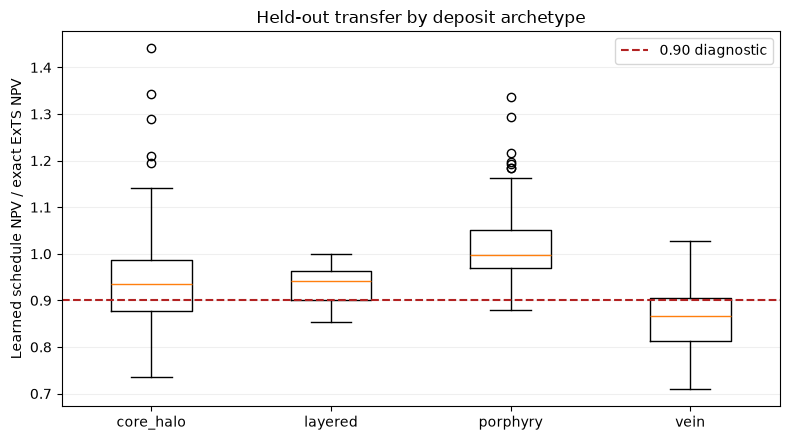

In [11]:
# Plot all held-out learned-to-ExTS ratios, retaining the failure tail.
archetypes = sorted({row['archetype'] for row in rows})
fig, ax = plt.subplots(figsize=(8,4.5))
series = [[row['vs_true'] for row in rows if row['archetype']==name] for name in archetypes]
ax.boxplot(series, tick_labels=archetypes, showfliers=True)
ax.axhline(.90,color='firebrick',linestyle='--',label='0.90 diagnostic')
ax.set(ylabel='Learned schedule NPV / exact ExTS NPV',title='Held-out transfer by deposit archetype')
ax.legend()
ax.grid(axis='y',alpha=.2)
fig.tight_layout()
plt.show()

The spread is decision-relevant: the 0.90 line is a diagnostic convention, not a theorem or universal acceptance criterion. Each point comes from a held-out deposit-scenario case; weak ratios remain visible instead of being hidden by the median. Similar performance across one generated family would still not establish transfer to conditioned mine geology. The archetype grouping diagnoses this synthetic study only, and its label may be unavailable for a real deposit.

Compare the greedy-baseline win rate separately. It is not interchangeable with the exact ExTS ratio and helps explain why a weak baseline should not define the product's success claim.

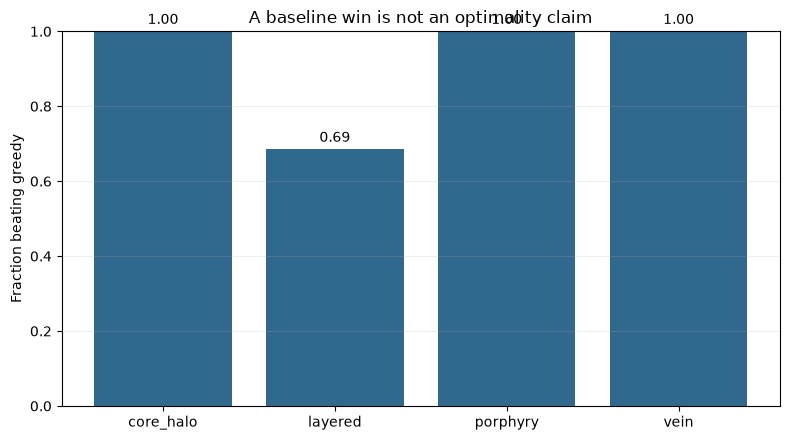

In [12]:
# Plot the fraction of cases beating the constructive greedy baseline.
wins = []
for name in archetypes:
    group = [row for row in rows if row['archetype']==name]
    wins.append(sum(bool(row['beats_greedy']) for row in group)/len(group))
fig, ax = plt.subplots(figsize=(8,4.5))
ax.bar(archetypes,wins,color='#31688e')
ax.set(ylim=(0,1),ylabel='Fraction beating greedy',title='A baseline win is not an optimality claim')
for i,value in enumerate(wins):
    ax.text(i,value+.02,f'{value:.2f}',ha='center')
ax.grid(axis='y',alpha=.2)
fig.tight_layout()
plt.show()

Beating a constructive greedy schedule is a weaker claim than matching exact ExTS. Read this chart beside the NPV-ratio distribution and the paired schedule comparison. The policy remains a feasible-schedule heuristic; it does not replace certified LP bounds or exact optimization on tractable cases. When a same-case exact comparator is unavailable, the product should label the result unscored rather than infer success from transfer metrics.

## Results

**Answer:** The executed study reports median learned-to-exact-ExTS NPV 0.9405, minimum 0.7101, and 33.56% of held-out cases below 0.90. It beats greedy in 92.13% of cases. This is useful but uneven transfer, not a general guarantee.

## Summary

Read the result at three scales: individual deposit, archetype summary, and aggregate holdout. The first catches catastrophic transfer, the second reveals structured heterogeneity, and the third communicates a compact central tendency. None replaces the others. Avoid using the aggregate median as a release promise or as a label for unseen real deposits. The experiment's decision boundary is a feasible CPIT plan under the declared two-resource scenario. It does not optimize destination choice, mine access, blending, equipment assignment, or operational recourse. Those constraints can change block priorities and should be modeled before transferring this policy into a production planning decision.

## References

CAOS PhaseFlow source and models: https://github.com/fsantibanezleal/CAOS_PhaseFlow; Kingma and Ba, Adam: https://arxiv.org/abs/1412.6980; Newman, Open-Pit Block-Sequencing Formulations: https://doi.org/10.1287/inte.2013.0731; Blom, Pearce and Cote, Large Neighbourhood Search: https://arxiv.org/abs/2403.18213.